# 10 — Clasificación sectorial: Fase 3
Ruta canónica. El antiguo prefijo 08 es solo un alias de compatibilidad.


**Entorno y fuentes verificadas**

Se utiliza el módulo reproducible del sprint y las dependencias existentes. La raíz se localiza desde el notebook o el repositorio.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
while not (ROOT / 'src').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / 'data/processed/panel_financiero_macro_bursatil.csv').is_file()
sys.path.insert(0, str(ROOT))
from src.clasificacion_sectorial import run
OUT = ROOT / 'reports/sprint_07'
datos, tablas, auditoria = run(ROOT)
display(pd.Series({k:auditoria[k] for k in ['observaciones','empresas','elegibles','empresas_elegibles','periodo']}))

observaciones                 4221
empresas                       336
elegibles                     3560
empresas_elegibles             309
periodo               [2005, 2025]
dtype: object

**Interpretación de la muestra**

El panel conserva 4.221 observaciones y 336 empresas; 3.560 observaciones de 309 empresas cumplen la elegibilidad original. Las comparaciones exactas preservan valores financieros y particiones del Sprint 06.

**Auditoría sectorial y monetaria**

Se cuantifican empresas, observaciones, disponibilidad de FCL y particiones elegibles por sector y moneda. Ejercicio y año objetivo mantienen sus funciones originales.

In [2]:
display(tablas['auditoria_sector_moneda.csv'])
display(pd.Series(auditoria['particiones_elegibles']))

,TipoSector,Moneda,empresas,observaciones,anio_min,anio_max,anios_cubiertos,anios,entrenamiento_elegible,prueba_elegible,...,fcl_disponible,fcl_faltante_pct,ciiu_faltante,fcl_mediana,fcl_desviacion,fcl_riq,fcl_asimetria,fcl_extremos_riq,participacion_panel_pct,muestra_insuficiente
0,A.F.P.,Soles,6,85,2005,2025,21,2005|2006|2007|2008|2009|2010|2011|2012|2013|2...,63,16,...,85,0.000000,77,102031.0,6.367934e+04,94074.00,-0.561034,1,2.013741,False
1,AGRICOLAS,D lares,2,3,2014,2018,3,2014|2015|2018,1,0,...,3,0.000000,3,-472.0,3.677888e+04,32228.50,1.728653,0,0.071073,True
2,AGRICOLAS,Soles,16,270,2005,2025,21,2005|2006|2007|2008|2009|2010|2011|2012|2013|2...,201,47,...,268,0.740741,246,1166.5,3.171106e+04,21189.50,1.964067,37,6.396588,False
3,BANCOS,Soles,24,393,2005,2025,21,2005|2006|2007|2008|2009|2010|2011|2012|2013|2...,172,82,...,260,33.842239,349,26827.5,2.259390e+06,543509.50,2.580117,59,9.310590,False
4,DIVERSOS,D lares,16,100,2005,2025,21,2005|2006|2007|2008|2009|2010|2011|2012|2013|2...,57,21,...,93,7.000000,88,8597.0,6.118856e+04,28468.00,2.309212,18,2.369107,False
5,DIVERSOS,Soles,104,1034,2005,2025,21,2005|2006|2007|2008|2009|2010|2011|2012|2013|2...,714,160,...,973,5.899420,955,2264.0,2.640406e+05,31252.00,-24.978792,210,24.496565,False
6,FINANCIERAS,Soles,21,258,2005,2025,21,2005|2006|2007|2008|2009|2010|2011|2012|2013|2...,123,57,...,188,27.131783,230,-3165.0,3.261582e+05,126489.50,-1.779630,27,6.112296,False
7,INDUSTRIALES,D lares,11,107,2005,2025,21,2005|2006|2007|2008|2009|2010|2011|2012|2013|2...,71,24,...,106,0.934579,95,6088.5,2.461494e+05,53070.00,-4.307182,25,2.534944,False
8,INDUSTRIALES,Soles,68,739,2005,2025,21,2005|2006|2007|2008|2009|2010|2011|2012|2013|2...,582,78,...,729,1.353180,701,6305.0,2.762742e+05,41786.00,2.443309,150,17.507700,False
9,INDUSTRIALES DEL TRABAJO,Soles,1,6,2005,2010,6,2005|2006|2007|2008|2009|2010,5,0,...,6,0.000000,6,5579.0,6.952376e+03,9273.25,0.575049,0,0.142146,True


entrenamiento    2869
prueba            691
dtype: int64

**Interpretación sectorial**

Los sectores SMV mezclan actividades de distinta naturaleza económica. Las estadísticas monetarias se calculan dentro de cada moneda y las 691 observaciones de prueba se conservan sin intervenir en el diseño de reglas.

**Identidad y códigos de actividad**

Los códigos ausentes, los cambios y las inconsistencias se diagnostican sin corregir el origen. Múltiples códigos pueden reflejar migración de revisión.

In [3]:
display(pd.Series({k:auditoria[k] for k in ['ciiu_faltantes_registros','empresas_sin_ciiu_en_todo_historial','empresas_multiples_ciiu','empresas_cambio_sector','empresas_multiples_ruc','ruc_compartido_entre_rpj']}))
display(tablas['identificadores_ruc_compartidos.csv'])

ciiu_faltantes_registros               3872
empresas_sin_ciiu_en_todo_historial     158
empresas_multiples_ciiu                   6
empresas_cambio_sector                    0
empresas_multiples_ruc                    0
ruc_compartido_entre_rpj                  1
dtype: int64

,RPJ,RUC,NombreEmpresa
1725,B60051,0,CREDICORP LTD.
2359,CD0010,0,INTERCORP PERU LTD.
2964,J01554,0,NUAM INTERNACIONAL SPA
3437,OE2305,0,INTERCORP FINANCIAL SERVICES INC.
3503,OE3161,0,MINERA IRL LIMITED
3920,OE5087,0,INRETAIL PERU CORP.


**Interpretación de cobertura CIIU**

Hay 3.872 registros sin CIIU; los 349 códigos observados se concentran en 2023–2025 y no declaran revisión. Seis empresas presentan múltiples CIIU y un RUC corresponde a más de un RPJ: son señales de revisión, no cambios económicos demostrados.

**Correspondencias trazables**

Se conserva el vocabulario oficial y la evidencia por observación. La jerarquía es una propuesta del proyecto y no una equivalencia oficial NYU–SMV.

In [4]:
display(pd.Series({k:auditoria[k] for k in ['empresas_con_alguna_clasificacion','empresas_completamente_clasificadas','industrias_identificadas','empresas_con_registros_pendientes','registros_clasificados']}))
display(tablas['catalogo_correspondencias.csv'].loc[lambda d:d.industria_damodaran.notna()].drop_duplicates(['RPJ','industria_damodaran','regla_industria']))

empresas_con_alguna_clasificacion        7
empresas_completamente_clasificadas      6
industrias_identificadas                 2
empresas_con_registros_pendientes      330
registros_clasificados                  87
dtype: int64

,RPJ,RUC,NombreEmpresa,Ejercicio,CIIU,TipoSector,ciiu_normalizado,revision_ciiu,macrosector_propuesto,sector_propuesto,regla_macrosector,industria_damodaran,regla_industria,candidatas_revision,fuente_regla,cambio_sector_posible,identificador_inconsistente,estado_clasificacion,version_clasificacion,fecha_consulta
475,AFP002,20157036794,AFP INTEGRA,2005,<NA>,A.F.P.,<NA>,No declarada en el panel,Financiero,A.F.P.,M01: agrupación analítica del TipoSector obser...,Investments & Asset Management,D01: AFP; administración de fondos previsionales,,https://www.sbs.gob.pe/sistema-privado-de-pens...,False,False,Clasificado por regla,Damodaran January 2026 / sprint07-v1,2026-10-23
496,AFP004,20142829551,PROFUTURO AFP,2005,<NA>,A.F.P.,<NA>,No declarada en el panel,Financiero,A.F.P.,M01: agrupación analítica del TipoSector obser...,Investments & Asset Management,D01: AFP; administración de fondos previsionales,,https://www.sbs.gob.pe/sistema-privado-de-pens...,False,False,Clasificado por regla,Damodaran January 2026 / sprint07-v1,2026-10-23
517,AFP005,20143980821,AFP HORIZONTE S.A.,2005,<NA>,A.F.P.,<NA>,No declarada en el panel,Financiero,A.F.P.,M01: agrupación analítica del TipoSector obser...,Investments & Asset Management,D01: AFP; administración de fondos previsionales,,https://www.sbs.gob.pe/sistema-privado-de-pens...,False,False,Clasificado por regla,Damodaran January 2026 / sprint07-v1,2026-10-23
525,AFP008,20170124449,AFP UNION VIDA S A,2005,<NA>,A.F.P.,<NA>,No declarada en el panel,Financiero,A.F.P.,M01: agrupación analítica del TipoSector obser...,Investments & Asset Management,D01: AFP; administración de fondos previsionales,,https://www.sbs.gob.pe/sistema-privado-de-pens...,False,False,Clasificado por regla,Damodaran January 2026 / sprint07-v1,2026-10-23
1707,B60004,20104347691,INVERSIONES EN TURISMO S.A. INVERTUR,2024,5510.0,DIVERSOS,5510,No declarada en el panel,Servicios de consumo,Alojamiento,M02: actividad CIIU 5510 verificada en revisio...,Hotel/Gaming,D02: CIIU 5510; alojamiento compatible en revi...,,https://unstats.un.org/unsd/classifications/Ec...,False,False,Clasificado por regla,Damodaran January 2026 / sprint07-v1,2026-10-23
3308,OE1928,20510398158,PRIMA AFP S.A.,2005,<NA>,A.F.P.,<NA>,No declarada en el panel,Financiero,A.F.P.,M01: agrupación analítica del TipoSector obser...,Investments & Asset Management,D01: AFP; administración de fondos previsionales,,https://www.sbs.gob.pe/sistema-privado-de-pens...,False,False,Clasificado por regla,Damodaran January 2026 / sprint07-v1,2026-10-23
3690,OE4132,20551464971,AFP HABITAT S.A.,2013,<NA>,A.F.P.,<NA>,No declarada en el panel,Financiero,A.F.P.,M01: agrupación analítica del TipoSector obser...,Investments & Asset Management,D01: AFP; administración de fondos previsionales,,https://www.sbs.gob.pe/sistema-privado-de-pens...,False,False,Clasificado por regla,Damodaran January 2026 / sprint07-v1,2026-10-23


**Interpretación de la clasificación**

Las reglas respaldan 7 empresas y 2 industrias: Investments & Asset Management y Hotel/Gaming. Seis empresas tienen clasificación completa; una tiene solo registros recientes clasificados. Las 330 empresas con algún registro pendiente requieren evidencia adicional. No se extienden CIIU recientes hacia ejercicios anteriores.

**Distribución y heterogeneidad intrasectorial**

Mediana, desviación, RIQ y asimetría describen el FCL contemporáneo por industria-moneda. La señal muestral orientativa no excluye observaciones.

In [5]:
display(tablas['distribucion_industria.csv'])
display(tablas['distribucion_industria.csv'].loc[lambda d:d.muestra_insuficiente,['industria_analisis','Moneda','empresas','entrenamiento_elegible','prueba_elegible']])

,industria_analisis,Moneda,empresas,observaciones,anio_min,anio_max,anios_cubiertos,anios,entrenamiento_elegible,prueba_elegible,...,fcl_disponible,fcl_faltante_pct,ciiu_faltante,fcl_mediana,fcl_desviacion,fcl_riq,fcl_asimetria,fcl_extremos_riq,participacion_panel_pct,muestra_insuficiente
0,Hotel/Gaming,Soles,1,2,2024,2025,2,2024|2025,0,1,...,2,0.000000,0,2090.0,3498.764353,2474.00,NaN,0,0.047382,True
1,Investments & Asset Management,Soles,6,85,2005,2025,21,2005|2006|2007|2008|2009|2010|2011|2012|2013|2...,63,16,...,85,0.000000,77,102031.0,63679.344735,94074.00,-0.561034,1,2.013741,False
2,Pendiente de revisión,D lares,56,524,2005,2025,21,2005|2006|2007|2008|2009|2010|2011|2012|2013|2...,353,92,...,506,3.435115,476,23304.0,310996.753395,101161.75,1.278728,77,12.414120,False
3,Pendiente de revisión,Soles,309,3610,2005,2025,21,2005|2006|2007|2008|2009|2010|2011|2012|2013|2...,2453,582,...,3305,8.448753,3319,8116.0,699680.516044,67629.00,7.563607,652,85.524757,False


,industria_analisis,Moneda,empresas,entrenamiento_elegible,prueba_elegible
0,Hotel/Gaming,Soles,1,0,1


**Interpretación intrasectorial**

La cobertura industrial es parcial y la categoría pendiente domina el panel. Los grupos pequeños no justifican aún modelos independientes; el FCL de entidades financieras no equivale a FCFF industrial. Los valores extremos se identifican y conservan.

**Composición de empresas**

Los conteos se realizan con RPJ únicos por grupo y pueden solaparse cuando una empresa tiene asignaciones parciales.

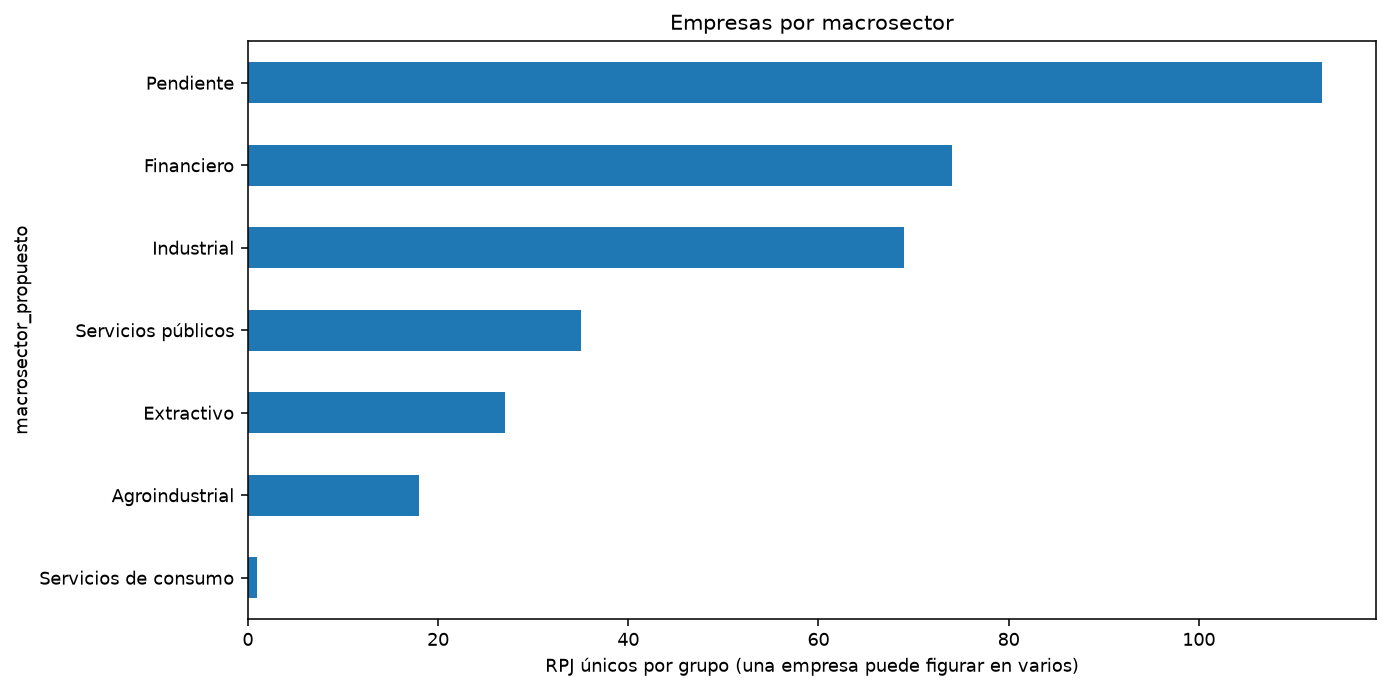

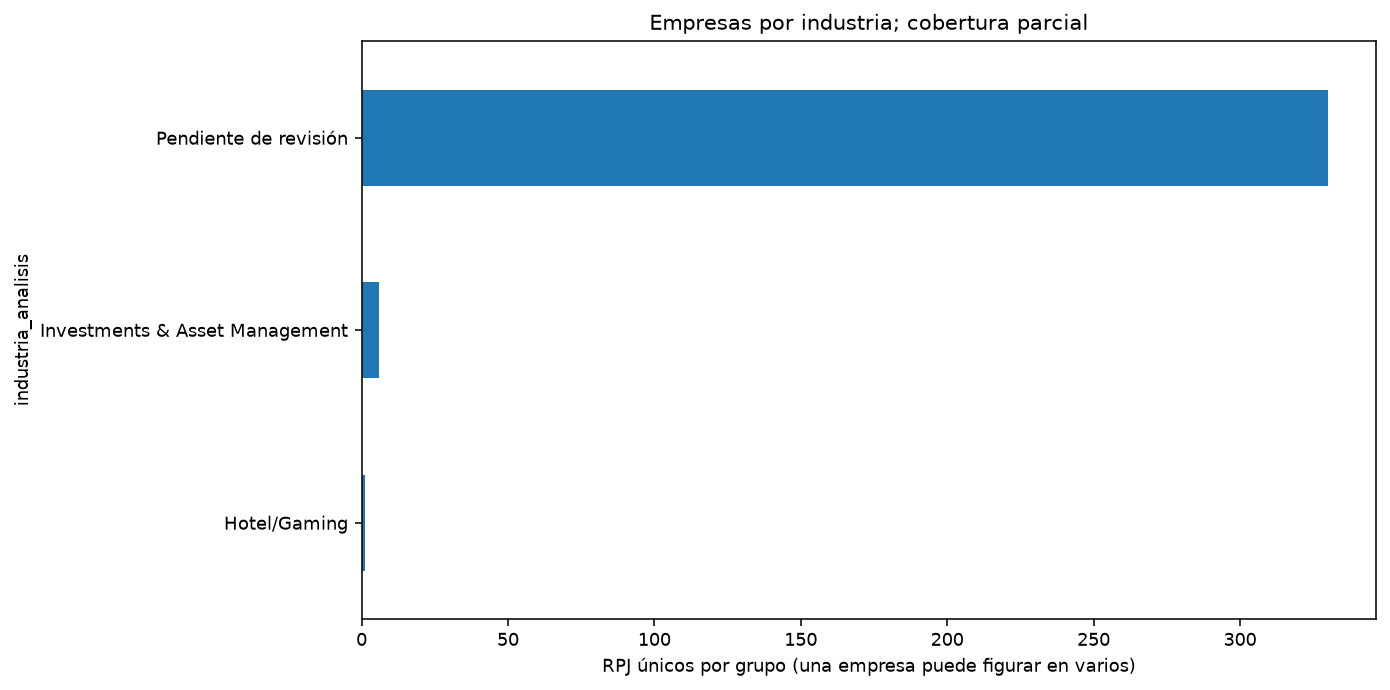

In [6]:
display(Image(filename=str(OUT/'empresas_macrosector.png')))
display(Image(filename=str(OUT/'empresas_industria.png')))

**Interpretación de composición**

La agregación por macrosector aporta una primera segmentación, mientras la distribución industrial muestra explícitamente la incertidumbre pendiente. La suma de conteos empresariales entre grupos puede superar 336 por clasificación parcial.

**Cobertura y moneda**

Las matrices cubren los 21 ejercicios. La distribución monetaria describe conteos y no suma magnitudes financieras incompatibles.

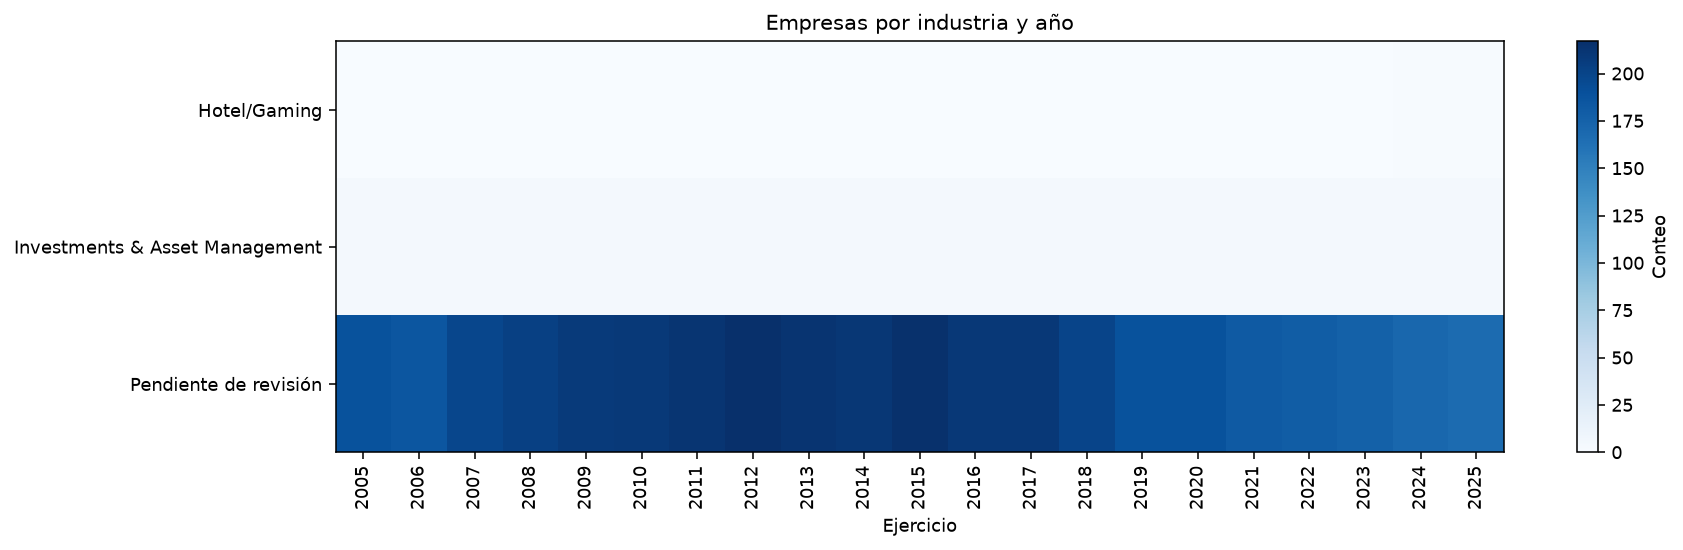

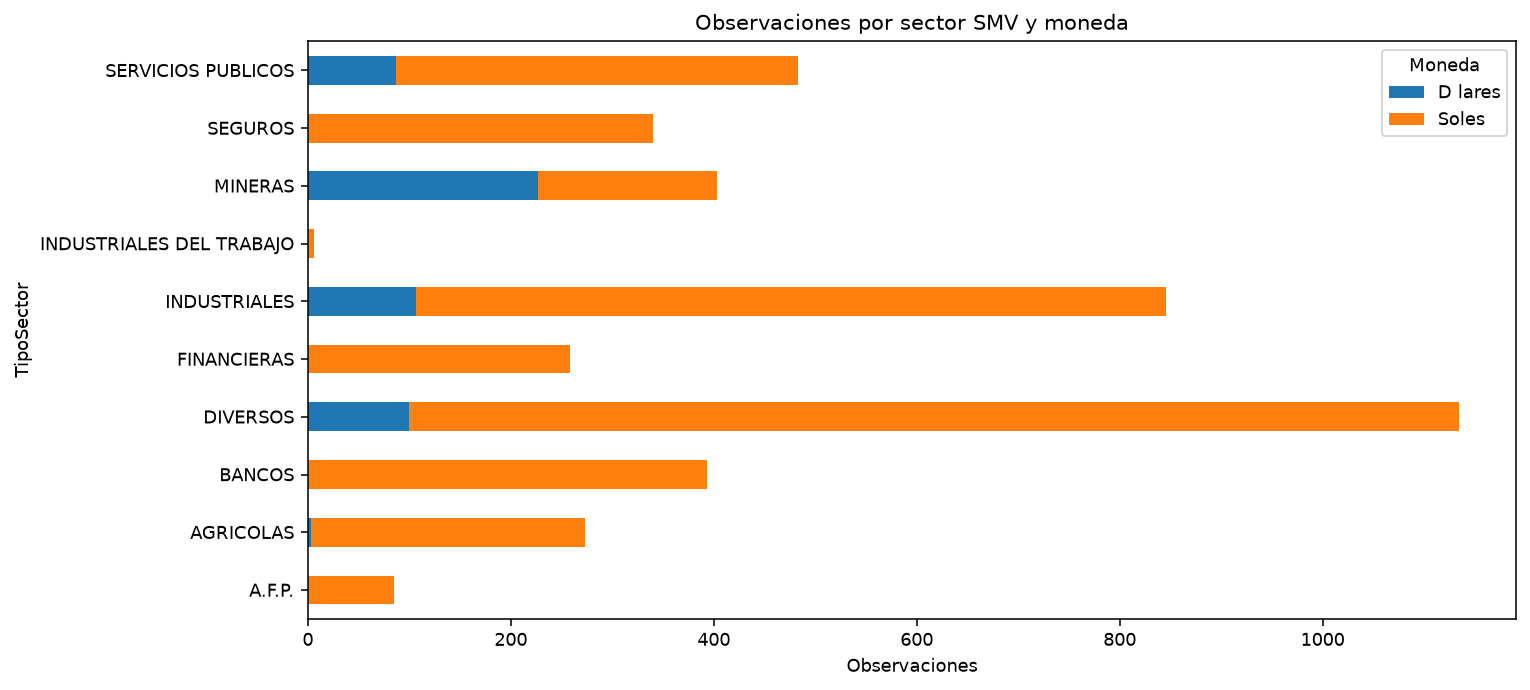

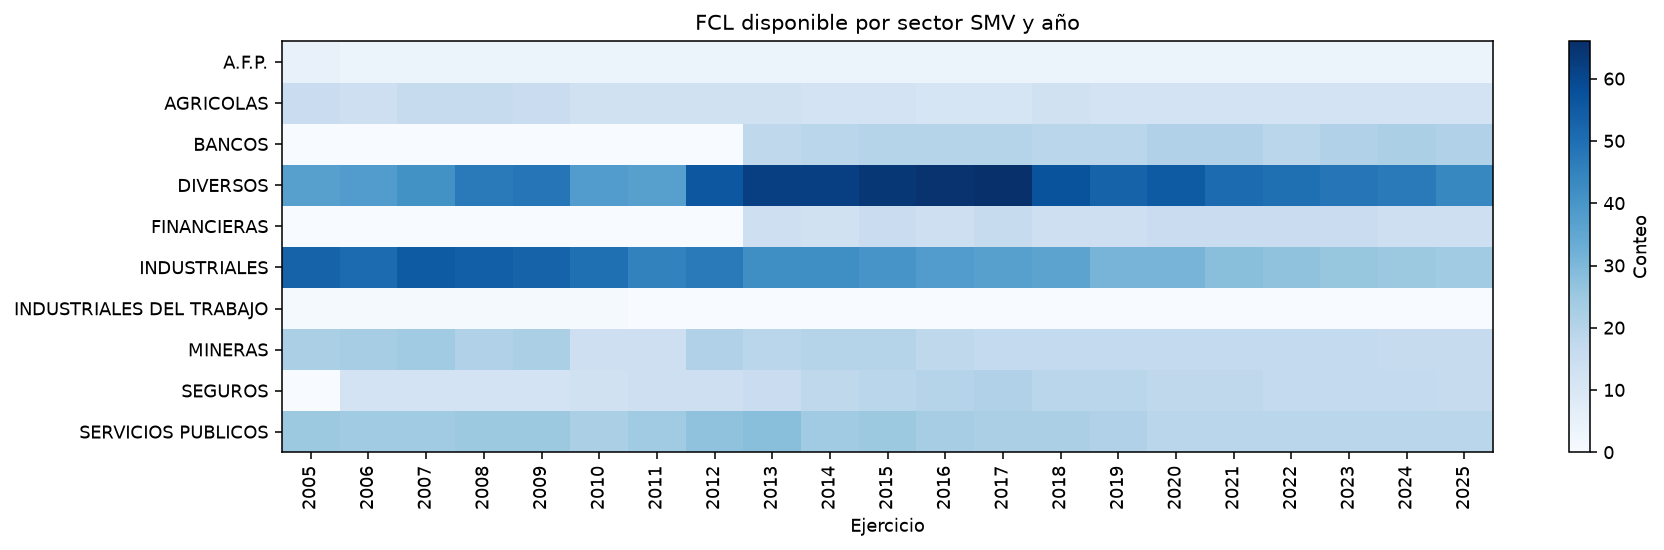

In [7]:
display(Image(filename=str(OUT/'cobertura_temporal.png')))
display(Image(filename=str(OUT/'sector_moneda.png')))
display(Image(filename=str(OUT/'disponibilidad_sector_anio.png')))

**Interpretación temporal**

La cobertura de una industria depende de la evidencia contemporánea, además de la presencia de estados financieros. Un cero de clasificación no demuestra ausencia histórica de actividad. La moneda original se conserva, incluida la etiqueta D lares.

**Distribución del flujo de caja**

Los diagramas separan monedas y utilizan eje symlog para mostrar signos y extremos sin recortar valores.

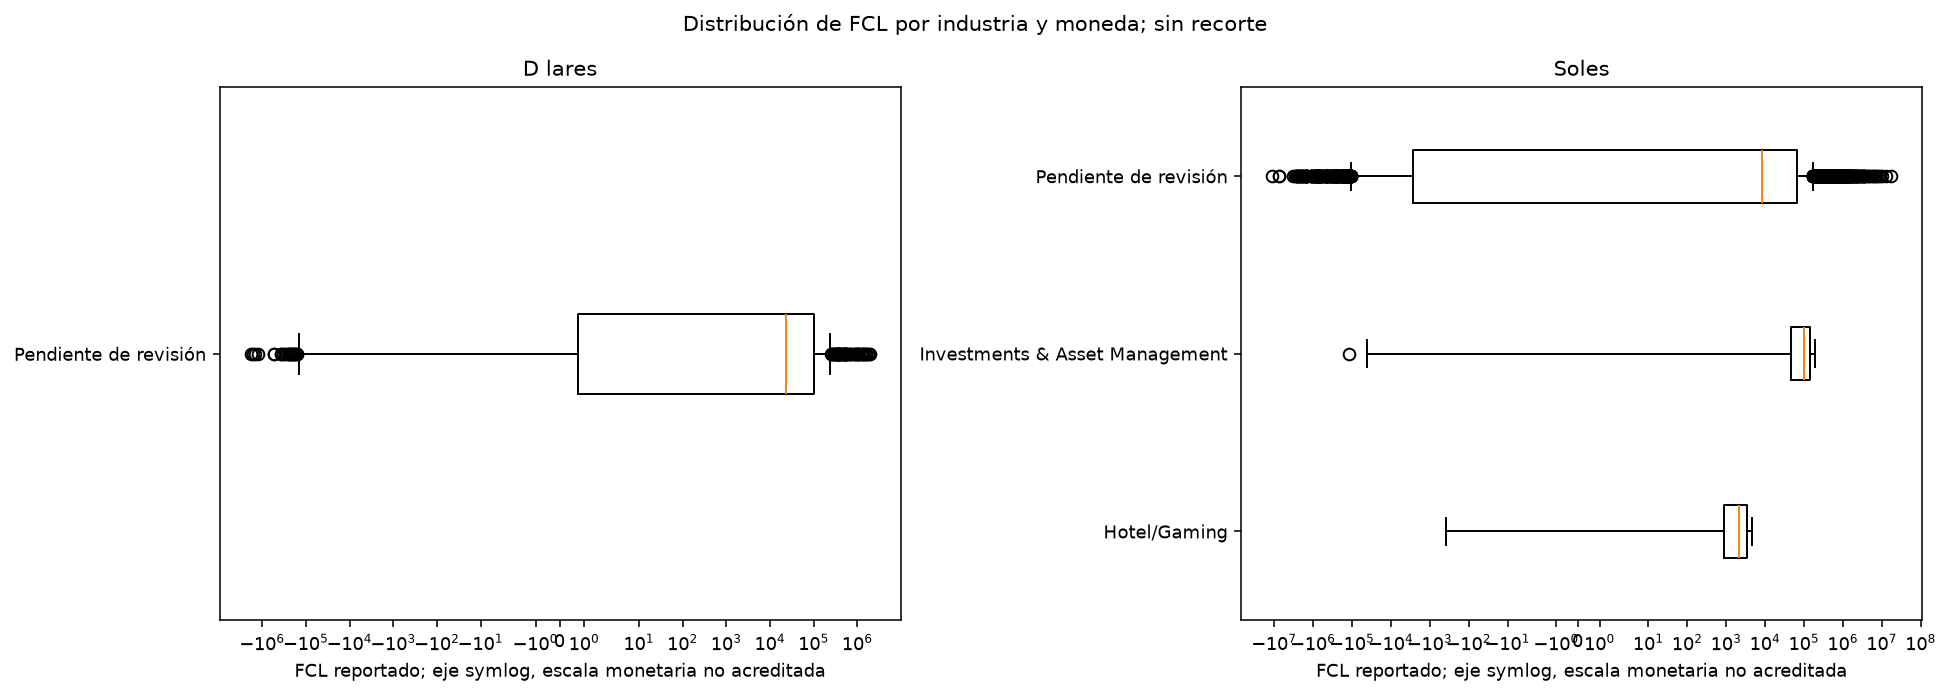

In [8]:
display(Image(filename=str(OUT/'fcl_industria.png')))

**Interpretación del FCL**

La dispersión y los extremos deben interpretarse dentro de cada moneda y con cautela por escala monetaria no acreditada. La aproximación FCO más CAPEX reportado no certifica FCFF ni comparabilidad económica entre entidades financieras y productivas.

**Integridad y entregables**

Los controles verifican uniones uno a uno y conservación exacta del panel. Los hashes permiten contrastar fuentes y resultados previos.

In [9]:
assert all(auditoria['controles'].values())
display(pd.Series(auditoria['controles']))
display(pd.DataFrame([{'archivo':k,'filas':len(v),'columnas':len(v.columns)} for k,v in tablas.items()]))

union_sin_perdidas              True
sin_duplicados_empresa_anio     True
valores_originales_exactos      True
particiones_iguales_sprint06    True
archivos_previos_preservados    True
dtype: bool

,archivo,filas,columnas
0,catalogo_correspondencias.csv,4221,20
1,casos_pendientes.csv,4134,20
2,distribucion_industria.csv,4,22
3,auditoria_sector_moneda.csv,15,22
4,distribucion_macrosector.csv,12,22
5,cobertura_sector_anio.csv,282,6
6,empresas_clasificacion.csv,336,11
7,identificadores_ruc_compartidos.csv,6,3
8,casos_cambio_sector.csv,0,20


**Propuesta para el siguiente sprint**

Separar banca, seguros, otras financieras y AFP; evaluar agroindustria, industria, extracción y servicios públicos dentro de cada moneda. Resolver primero revisión CIIU y actividad empresarial, mantener pendientes y grupos pequeños, y reservar la validación temporal para entrenamiento futuro. El documento metodológico detalla límites y reglas.

**Ampliación documental — Corrección de cobertura**

La primera pasada se conserva como referencia. La segunda añade actividad principal y períodos respaldados por fuentes primarias, con un maestro empresarial y evidencia por empresa-año.

**Catálogo documental reproducible**

Se verifican pasajes, hashes y celdas de fuentes congeladas, preservando las reglas originales y todas las columnas financieras.

In [10]:
from src.enriquecimiento_sectorial import run as run_documental
datos_documentales, tablas_documentales, auditoria_documental = run_documental(ROOT)
display(tablas_documentales['comparacion_cobertura.csv'])

,indicador,anterior,nueva,diferencia
0,empresas,336,336,0
1,observaciones,4221,4221,0
2,empresas_clasificadas,6,13,7
3,empresas_parcialmente_clasificadas,1,45,44
4,empresas_pendientes,329,278,-51
5,empresas_con_alguna_clasificacion,7,58,51
6,observaciones_clasificadas,87,463,376
7,observaciones_pendientes,4134,3758,-376
8,industrias,2,16,14


**Interpretación de cobertura**

Las empresas con alguna observación clasificada aumentan de 7 a 49 y las observaciones de 87 a 442. Hay 12 empresas con cobertura completa, 37 parcial y 287 sin observaciones clasificadas; las industrias presentes pasan de 2 a 13. Las 3.779 observaciones pendientes se conservan.

**Maestro empresarial y calidad de identidad**

El maestro mantiene 336 RPJ y distingue validación formal de RUC de consulta registral SUNAT. Los estados históricos son mutuamente excluyentes.

In [11]:
maestro = tablas_documentales['catalogo_maestro_empresas.csv']
display(maestro[['RPJ','NombreEmpresa','RUC_valido_formal','actividad_principal_documentada','anio_referencia_actividad','estado_clasificacion','observaciones_clasificadas','observaciones_pendientes']])
display(maestro.estado_clasificacion.value_counts())

,RPJ,NombreEmpresa,RUC_valido_formal,actividad_principal_documentada,anio_referencia_actividad,estado_clasificacion,observaciones_clasificadas,observaciones_pendientes
0,000355,COSAPI S.A.,20100082391,Ejecución de obras de ingeniería y construcción,2024,Parcialmente clasificada,2,8
1,000432,SUPERMERCADOS PERUANOS S.A.,20100070970,Operación de cadena de supermercados y tiendas...,2019,Parcialmente clasificada,1,13
2,000683,CONSORCIO INDUSTRIAL DE AREQUIPA SA,20100195080,,,Pendiente,0,19
3,000717,SAN FERNANDO S.A.,20100154308,,,Pendiente,0,9
4,000981,YARA PERU S.R.L.,20100193117,,,Pendiente,0,5
...,...,...,...,...,...,...,...,...
331,SP0010,SOCIEDAD ELECTRICA DEL SUR OESTE S.A. - SEAL,20100188628,Empresa de servicio público eléctrico: Activid...,2024,Parcialmente clasificada,18,3
332,SP0012,SERVICIO DE AGUA POTABLE Y ALCANTARILLADO - SE...,20100152356,,,Pendiente,0,19
333,TI0001,MOTORES DIESEL ANDINOS S.A.,20417926632,,,Pendiente,0,16
334,TI0002,INTRADEVCO INDUSTRIAL S.A.,20417378911,,,Pendiente,0,14


estado_clasificacion
Pendiente                   278
Parcialmente clasificada     45
Clasificada                  13
Name: count, dtype: int64

**Interpretación empresarial**

Se revisaron fuentes SMV locales para las 336 empresas y documentación específica para 56. Los 330 RUC válidos cumplen controles formales, sin certificar estado SUNAT. Las seis entidades extranjeras con RUC original 0 se mantienen sin inventar identificadores.

**Evidencia de actividad y CIIU**

Cada decisión registra fuente primaria, página o celdas, ejercicios y certeza. Los códigos documentales se conservan separados del CIIU original.

In [12]:
display(tablas_documentales['evidencias_actividad.csv'][['evidencia_id','RPJ','actividad_principal','anios_respaldados','industria_propuesta','certeza_correspondencia','tipo_fuente','pagina_pdf','hoja','celdas']])
display(tablas_documentales['correspondencia_actividad_ciiu_industria.csv'].head(12))

,evidencia_id,RPJ,actividad_principal,anios_respaldados,industria_propuesta,certeza_correspondencia,tipo_fuente,pagina_pdf,hoja,celdas
0,E001,CM0006,Extracción y producción de cobre y molibdeno,2024,Metals & Mining,Alta,PDF,14,,
1,E002,CM0001,Exploración y explotación de minerales polimet...,2024,Metals & Mining,Alta,PDF,13,,
2,E003,B20041,Extracción y fundición de oro para producir or...,2024,Precious Metals,Alta,PDF,11,,
3,E004,B20016,"Producción de concentrados de zinc, plomo y cobre",2023|2024,Metals & Mining,Alta,PDF,12,,
4,E005,B20026,Extracción y comercialización de concentrados ...,2024|2025,Metals & Mining,Alta,PDF,13,,
...,...,...,...,...,...,...,...,...,...,...
80,M020,SP0006,Empresa de servicio público eléctrico: Activid...,2008|2009|2010|2011|2012|2013|2016|2018|2019|2...,Power,Alta,XLSX,,10.17.3 y 4 Publica y Gub,P25|Q25|R25|S25|T25|U25|X25|Z25|AA25|AB25|AC25...
81,M021,B40005,Empresa de servicio público eléctrico: Activid...,2005|2006|2007|2008|2009|2010|2011|2012|2013|2...,Power,Alta,XLSX,,10.17.3 y 4 Publica y Gub,M26|N26|O26|P26|Q26|R26|S26|T26|U26|V26|W26|X2...
82,M022,B40006,Empresa de servicio público eléctrico: Activid...,2010|2011|2012|2013|2014|2018|2019|2020|2021|2...,Power,Alta,XLSX,,10.17.3 y 4 Publica y Gub,R34|S34|T34|U34|V34|Z34|AA34|AB34|AC34|AD34|AE...
83,M023,B40002,Empresa de servicio público eléctrico: Activid...,2005|2006|2007|2008|2009|2010|2011|2012|2013|2...,Power,Alta,XLSX,,10.17.3 y 4 Publica y Gub,M35|N35|O35|P35|Q35|R35|S35|T35|U35|V35|X35|Y3...


,RPJ,RUC,NombreEmpresa,Ejercicio,actividad_documentada,CIIU,ciiu_normalizado,ciiu_smv_documental,ciiu_documental,revision_ciiu_documental,industria_candidata_documental,industria_damodaran,regla_industria,evidencias_documentales,fuente_documental,pagina_documental,hoja_documental,celdas_documentales
5,000355,20100082391,COSAPI S.A.,2020,Ingeniería y construcción como negocio princip...,<NA>,<NA>,,4390,Rev. 4,Engineering/Construction,Engineering/Construction,D03: actividad principal documentada; años y e...,E020|F3_009,https://www.cosapi.com.pe/Upload/documento/mis...,5 ; 8,,
9,000355,20100082391,COSAPI S.A.,2024,Ejecución de obras de ingeniería y construcción,4390.0,4390,4390,4390,No declarada,Engineering/Construction,Engineering/Construction,D03: actividad principal documentada; años y e...,E019,https://www.cosapi.com.pe/Upload/documento/mis...,28,,
23,000432,20100070970,SUPERMERCADOS PERUANOS S.A.,2018,Operación de cadena de supermercados y tiendas...,<NA>,<NA>,,,,Retail (Grocery and Food),Retail (Grocery and Food),D03: actividad principal documentada; años y e...,F3_007,https://archivos.bvl.com.pe/eeff/000432/201904...,6,,
104,002597,20217427593,SOCIEDAD MINERA CORONA S.A.,2025,Producción y comercialización de concentrados ...,729.0,0729,0729,,,Metals & Mining,Metals & Mining,D03: actividad principal documentada; años y e...,E006,https://www.smv.gob.pe/ConsultasP8/temp/EEFF%2...,12,,
139,002766,20259829594,REFINERIA LA PAMPILLA S.A.A.,2024,Operación de refinería de productos de petróle...,2320.0,2320,2320,,,,<NA>,P02: revisión CIIU no declarada o corresponden...,E037,https://www.repsol.pe/content/dam/repsol-paise...,1,,
141,002829,20333363900,ENGIE ENERGIA PERU S.A.A.,2005,Empresa de servicio público eléctrico: Activid...,<NA>,<NA>,,,,Power,Power,D04: actividad eléctrica MINEM por empresa-año...,M001,https://cdn.www.gob.pe/uploads/document/file/9...,,10.17.2 Inversion Privada,M64|N64|O64|P64|Q64|R64|S64|T64|U64|V64|W64|X6...
142,002829,20333363900,ENGIE ENERGIA PERU S.A.A.,2006,Empresa de servicio público eléctrico: Activid...,<NA>,<NA>,,,,Power,Power,D04: actividad eléctrica MINEM por empresa-año...,M001,https://cdn.www.gob.pe/uploads/document/file/9...,,10.17.2 Inversion Privada,M64|N64|O64|P64|Q64|R64|S64|T64|U64|V64|W64|X6...
143,002829,20333363900,ENGIE ENERGIA PERU S.A.A.,2007,Empresa de servicio público eléctrico: Activid...,<NA>,<NA>,,,,Power,Power,D04: actividad eléctrica MINEM por empresa-año...,M001,https://cdn.www.gob.pe/uploads/document/file/9...,,10.17.2 Inversion Privada,M64|N64|O64|P64|Q64|R64|S64|T64|U64|V64|W64|X6...
144,002829,20333363900,ENGIE ENERGIA PERU S.A.A.,2008,Empresa de servicio público eléctrico: Activid...,<NA>,<NA>,,,,Power,Power,D04: actividad eléctrica MINEM por empresa-año...,M001,https://cdn.www.gob.pe/uploads/document/file/9...,,10.17.2 Inversion Privada,M64|N64|O64|P64|Q64|R64|S64|T64|U64|V64|W64|X6...
145,002829,20333363900,ENGIE ENERGIA PERU S.A.A.,2009,Empresa de servicio público eléctrico: Activid...,<NA>,<NA>,,,,Power,Power,D04: actividad eléctrica MINEM por empresa-año...,M001,https://cdn.www.gob.pe/uploads/document/file/9...,,10.17.2 Inversion Privada,M64|N64|O64|P64|Q64|R64|S64|T64|U64|V64|W64|X6...


**Interpretación de trazabilidad**

D03 usa actividad documentada en los ejercicios explícitos. D04 combina una celda MINEM de inversión eléctrica positiva, identidad empresarial revisada y sector SMV de servicios públicos del mismo ejercicio. Un CIIU ausente sigue vacío; no se deducen códigos desde la actividad.

**Cobertura histórica y evidencia fuera del panel**

La serie histórica MINEM respalda sus propias celdas anuales. Los documentos sin observación coincidente no se trasladan a otros años.

In [13]:
display(tablas_documentales['evidencias_estadisticas_empresa_anio.csv'].head(15))
display(tablas_documentales['evidencias_sin_observacion_panel.csv'])
display(tablas_documentales['distribucion_industria.csv'])

,RPJ,Ejercicio,fuente_id,hoja,celda_nombre,nombre_minem,celda_actividad,actividad_minem,celda_anio,celda_valor,inversion_miles_usd,estado_inversion,estado_actividad,asignable_por_inversion,fuente_url,sha256_fuente,regla
0,002829,2005,minem24_cap10,10.17.2 Inversion Privada,B64,ENGIE ENERGIA PERU S.A.,B3,Actividad de generación,M3,M64,11653,Positiva,Indicio sectorial con inversión positiva,True,https://cdn.www.gob.pe/uploads/document/file/9...,35d5d385767b160de0a3c24b47f57d50d6e21ec6346fd7...,D04: indicio sectorial condicionado a inversió...
1,002829,2006,minem24_cap10,10.17.2 Inversion Privada,B64,ENGIE ENERGIA PERU S.A.,B3,Actividad de generación,N3,N64,56770,Positiva,Indicio sectorial con inversión positiva,True,https://cdn.www.gob.pe/uploads/document/file/9...,35d5d385767b160de0a3c24b47f57d50d6e21ec6346fd7...,D04: indicio sectorial condicionado a inversió...
2,002829,2007,minem24_cap10,10.17.2 Inversion Privada,B64,ENGIE ENERGIA PERU S.A.,B3,Actividad de generación,O3,O64,78712,Positiva,Indicio sectorial con inversión positiva,True,https://cdn.www.gob.pe/uploads/document/file/9...,35d5d385767b160de0a3c24b47f57d50d6e21ec6346fd7...,D04: indicio sectorial condicionado a inversió...
3,002829,2008,minem24_cap10,10.17.2 Inversion Privada,B64,ENGIE ENERGIA PERU S.A.,B3,Actividad de generación,P3,P64,69851,Positiva,Indicio sectorial con inversión positiva,True,https://cdn.www.gob.pe/uploads/document/file/9...,35d5d385767b160de0a3c24b47f57d50d6e21ec6346fd7...,D04: indicio sectorial condicionado a inversió...
4,002829,2009,minem24_cap10,10.17.2 Inversion Privada,B64,ENGIE ENERGIA PERU S.A.,B3,Actividad de generación,Q3,Q64,33109,Positiva,Indicio sectorial con inversión positiva,True,https://cdn.www.gob.pe/uploads/document/file/9...,35d5d385767b160de0a3c24b47f57d50d6e21ec6346fd7...,D04: indicio sectorial condicionado a inversió...
5,002829,2010,minem24_cap10,10.17.2 Inversion Privada,B64,ENGIE ENERGIA PERU S.A.,B3,Actividad de generación,R3,R64,88781,Positiva,Indicio sectorial con inversión positiva,True,https://cdn.www.gob.pe/uploads/document/file/9...,35d5d385767b160de0a3c24b47f57d50d6e21ec6346fd7...,D04: indicio sectorial condicionado a inversió...
6,002829,2011,minem24_cap10,10.17.2 Inversion Privada,B64,ENGIE ENERGIA PERU S.A.,B3,Actividad de generación,S3,S64,270138,Positiva,Indicio sectorial con inversión positiva,True,https://cdn.www.gob.pe/uploads/document/file/9...,35d5d385767b160de0a3c24b47f57d50d6e21ec6346fd7...,D04: indicio sectorial condicionado a inversió...
7,002829,2012,minem24_cap10,10.17.2 Inversion Privada,B64,ENGIE ENERGIA PERU S.A.,B3,Actividad de generación,T3,T64,490574,Positiva,Indicio sectorial con inversión positiva,True,https://cdn.www.gob.pe/uploads/document/file/9...,35d5d385767b160de0a3c24b47f57d50d6e21ec6346fd7...,D04: indicio sectorial condicionado a inversió...
8,002829,2013,minem24_cap10,10.17.2 Inversion Privada,B64,ENGIE ENERGIA PERU S.A.,B3,Actividad de generación,U3,U64,206693,Positiva,Indicio sectorial con inversión positiva,True,https://cdn.www.gob.pe/uploads/document/file/9...,35d5d385767b160de0a3c24b47f57d50d6e21ec6346fd7...,D04: indicio sectorial condicionado a inversió...
9,002829,2014,minem24_cap10,10.17.2 Inversion Privada,B64,ENGIE ENERGIA PERU S.A.,B3,Actividad de generación,V3,V64,281064.61239,Positiva,Indicio sectorial con inversión positiva,True,https://cdn.www.gob.pe/uploads/document/file/9...,35d5d385767b160de0a3c24b47f57d50d6e21ec6346fd7...,D04: indicio sectorial condicionado a inversió...


,evidencia_id,RPJ,Ejercicio,industria_propuesta,estado_evidencia,motivo
0,E024,014819,2023,Retail (Distributors),Asignable,Año documentado sin observación en panel; proh...
1,E024,014819,2024,Retail (Distributors),Asignable,Año documentado sin observación en panel; proh...
2,E025,000432,2024,Retail (Grocery and Food),Asignable,Año documentado sin observación en panel; proh...
3,E026,OE5506,2024,Education,Asignable,Año documentado sin observación en panel; proh...
4,E027,B80136,2024,Real Estate (Operations & Services),Asignable,Año documentado sin observación en panel; proh...
5,F3_007,000432,2019,Retail (Grocery and Food),Asignable,Año documentado sin observación en panel; proh...


,industria_analisis,Moneda,empresas,observaciones,anio_min,anio_max,anios_cubiertos,anios,entrenamiento_elegible,prueba_elegible,...,fcl_disponible,fcl_faltante_pct,ciiu_faltante,fcl_mediana,fcl_desviacion,fcl_riq,fcl_asimetria,fcl_extremos_riq,participacion_panel_pct,muestra_insuficiente
0,Building Materials,Soles,2,3,2020,2024,3,2020|2023|2024,1,2,...,3,0.000000,2,175555.0,150092.587795,146058.0,1.112054,0,0.071073,True
1,Engineering/Construction,Soles,1,2,2020,2024,2,2020|2024,1,0,...,2,0.000000,1,-62194.5,46849.359788,33127.5,NaN,0,0.047382,True
2,Farming/Agriculture,Soles,1,1,2024,2024,1,2024,0,1,...,1,0.000000,0,42017.0,NaN,0.0,NaN,0,0.023691,True
3,Financial Svcs. (Non-bank & Insurance),Soles,2,2,2024,2024,1,2024,0,2,...,2,0.000000,0,207039.0,55321.206133,39118.0,NaN,0,0.047382,True
4,Food Processing,D lares,1,2,2023,2024,2,2023|2024,0,2,...,2,0.000000,1,-5371.5,41683.237644,29474.5,NaN,0,0.047382,True
5,Food Processing,Soles,6,13,2019,2025,6,2019|2020|2021|2023|2024|2025,5,7,...,13,0.000000,7,66004.0,140789.548622,68288.0,0.554586,2,0.307984,True
6,Hotel/Gaming,Soles,1,2,2024,2025,2,2024|2025,0,1,...,2,0.000000,0,2090.0,3498.764353,2474.0,NaN,0,0.047382,True
7,Insurance (Life),Soles,1,2,2024,2025,2,2024|2025,0,1,...,2,0.000000,0,345900.0,18366.391535,12987.0,NaN,0,0.047382,True
8,Investments & Asset Management,Soles,6,85,2005,2025,21,2005|2006|2007|2008|2009|2010|2011|2012|2013|2...,63,16,...,85,0.000000,77,102031.0,63679.344735,94074.0,-0.561034,1,2.013741,False
9,Machinery,Soles,1,1,2024,2024,1,2024,0,1,...,1,0.000000,0,-3611.0,NaN,0.0,NaN,0,0.023691,True


**Interpretación temporal e intrasectorial**

La ampliación añade 355 asignaciones sin interpolar huecos. Cuatro empresas tienen industria documental en años que no coinciden con sus observaciones del panel; por ello sus registros históricos siguen pendientes. La inversión eléctrica acredita actividad sectorial, sin medir producción ni probar por sí sola la actividad principal de cualquier empresa.

**Casos para auditoría independiente**

Holdings, bancos y fronteras industriales ambiguas requieren revisión. La estabilidad se restringe a los años documentados.

In [14]:
display(tablas_documentales['cambios_actividad_revision.csv'])
display(maestro.loc[maestro.RPJ.isin(['B30121','023106','B80004','B80020','B20010']),['RPJ','NombreEmpresa','actividad_principal_documentada','certeza_industria','estado_temporal','motivo_pendiente']])
assert all(auditoria_documental['controles'].values())
display(pd.Series(auditoria_documental['controles']))

,RPJ,evento,fecha_reportada,fuente,estado,efecto
0,B30121,Reorganización de UNACEM hacia estructura holding,2022-01-01,https://www.smv.gob.pe/ConsultasP8/temp/HdI%20...,Reportado en fuente primaria indexada; copia o...,No atribuir producción de subsidiarias a la ma...


,RPJ,NombreEmpresa,actividad_principal_documentada,certeza_industria,estado_temporal,motivo_pendiente
33,023106,AENZA S.A.A.,Tenencia y gestión de inversiones y servicios ...,Pendiente,Actividad documentada; industria o coincidenci...,Industria/perímetro documental ambiguo
58,B20010,NEXA RESOURCES PERU S.A.A.,"Grupo de minería de zinc, cobre y plomo; activ...",Pendiente,Actividad documentada; industria o coincidenci...,Industria/perímetro documental ambiguo
87,B30121,UNACEM CORP SOCIEDAD ANONIMA ABIERTA - UNACEM ...,"Holding de inversiones en cemento, materiales ...",Pendiente,Actividad documentada; industria o coincidenci...,Industria/perímetro documental ambiguo
125,B80004,BANCO BBVA PERU,Intermediación financiera como banco múltiple ...,Pendiente,Actividad documentada; industria o coincidenci...,Industria/perímetro documental ambiguo
132,B80020,BANCO INTERNACIONAL DEL PERU S.A.A. - INTERBANK,Banco múltiple,Pendiente,Actividad documentada; industria o coincidenci...,Industria/perímetro documental ambiguo


sin_perdidas_ni_duplicados                   True
reglas_verificadas_preservadas               True
valores_financieros_y_particiones_exactos    True
fuentes_conservadas_y_pasajes_verificados    True
fase2_documentos_y_resultados_congelados     True
periodos_explicitos_sin_interpolacion        True
sin_entrenamiento                            True
bases_y_experimentos_previos_intactos        True
primera_entrega_sprint07_intacta             True
dtype: bool

**Interpretación y límites de la ampliación**

Las reglas verificadas y los 87 registros previamente clasificados permanecen intactos. La revisión externa específica aún no es exhaustiva para todas las empresas; la clasificación es retrospectiva y no certifica disponibilidad histórica en tiempo real. El informe de Antigravity detalla los pendientes y los juicios que deben revisarse antes de futuros modelos sectoriales.

**Correcciones de auditoría y cobertura de Fase 3.**
Comparación congelada, empresas distintas por partición y priorización documental.

In [15]:
display(tablas_documentales['comparacion_fase2_fase3.csv'])
display(tablas_documentales['suficiencia_muestral.csv'])
display(tablas_documentales['priorizacion_pendientes.csv'].head(20))

,indicador,fase2,fase3,diferencia
0,empresas,336,336,0
1,observaciones,4221,4221,0
2,empresas_clasificadas,12,13,1
3,empresas_parcialmente_clasificadas,37,45,8
4,empresas_pendientes,287,278,-9
5,empresas_con_alguna_clasificacion,49,58,9
6,observaciones_clasificadas,442,463,21
7,observaciones_pendientes,3779,3758,-21
8,industrias,13,16,3


,industria_damodaran,Moneda,empresas_panel,observaciones_panel,empresas_entrenamiento,empresas_prueba,observaciones_entrenamiento,observaciones_prueba,anios_entrenamiento,anios_prueba,supera_umbral_original,diversidad_empresarial_minima,muestra_suficiente_orientativa,muestra_insuficiente,nota
0,Building Materials,Soles,2,3,1,1,1,2,1,2,False,False,False,True,"Umbral original: >=5 RPJ en panel, >=30 filas ..."
1,Engineering/Construction,Soles,1,2,1,0,1,0,1,0,False,False,False,True,"Umbral original: >=5 RPJ en panel, >=30 filas ..."
2,Farming/Agriculture,Soles,1,1,0,1,0,1,0,1,False,False,False,True,"Umbral original: >=5 RPJ en panel, >=30 filas ..."
3,Financial Svcs. (Non-bank & Insurance),Soles,2,2,0,2,0,2,0,1,False,False,False,True,"Umbral original: >=5 RPJ en panel, >=30 filas ..."
4,Food Processing,D lares,1,2,0,1,0,2,0,2,False,False,False,True,"Umbral original: >=5 RPJ en panel, >=30 filas ..."
5,Food Processing,Soles,6,13,3,5,5,7,2,3,False,False,False,True,"Umbral original: >=5 RPJ en panel, >=30 filas ..."
6,Hotel/Gaming,Soles,1,2,0,1,0,1,0,1,False,False,False,True,"Umbral original: >=5 RPJ en panel, >=30 filas ..."
7,Insurance (Life),Soles,1,2,0,1,0,1,0,1,False,False,False,True,"Umbral original: >=5 RPJ en panel, >=30 filas ..."
8,Investments & Asset Management,Soles,6,85,5,4,63,16,16,4,True,False,False,False,"Umbral original: >=5 RPJ en panel, >=30 filas ..."
9,Machinery,Soles,1,1,0,1,0,1,0,1,False,False,False,True,"Umbral original: >=5 RPJ en panel, >=30 filas ..."


,prioridad,RPJ,NombreEmpresa,RUC,TipoSector,grupo_priorizacion,observaciones_pendientes,entrenamiento_elegible_pendiente,prueba_elegible_pendiente,total_elegible_pendiente,ambas_particiones,anios_entrenamiento_pendientes,anios_prueba_pendientes,motivo
0,1,017070,EMPRESA AZUCARERA EL INGENIO S.A.,20141723601,AGRICOLAS,No financiero,21,16,4,20,True,2005|2006|2007|2008|2009|2010|2011|2012|2013|2...,2021|2022|2023|2024,Recuperar evidencia primaria de la entidad y l...
1,2,019094,CENTRAL AZUCARERA CHUCARAPI-PAMPA BLANCA S.A.,20129854953,AGRICOLAS,No financiero,21,16,4,20,True,2005|2006|2007|2008|2009|2010|2011|2012|2013|2...,2021|2022|2023|2024,Recuperar evidencia primaria de la entidad y l...
2,3,020045,ACTIVO INMOBILIARIO PERUANO S.A.A. (ANTES FALA...,20260172035,DIVERSOS,No financiero,21,16,4,20,True,2005|2006|2007|2008|2009|2010|2011|2012|2013|2...,2021|2022|2023|2024,Recuperar evidencia primaria de la entidad y l...
3,4,A80069,LA POSITIVA SEGUROS Y REASEGUROS S.A.,20100210909,SEGUROS,Financiero,21,16,4,20,True,2005|2006|2007|2008|2009|2010|2011|2012|2013|2...,2021|2022|2023|2024,Recuperar evidencia primaria de la entidad y l...
4,5,B11068,AGROINDUSTRIAS SAN JACINTO S.A.A.,20116225779,AGRICOLAS,No financiero,21,16,4,20,True,2005|2006|2007|2008|2009|2010|2011|2012|2013|2...,2021|2022|2023|2024,Recuperar evidencia primaria de la entidad y l...
5,6,B11072,EMPRESA AGRARIA CHIQUITOY S.A.,20131835621,AGRICOLAS,No financiero,21,16,4,20,True,2005|2006|2007|2008|2009|2010|2011|2012|2013|2...,2021|2022|2023|2024,Recuperar evidencia primaria de la entidad y l...
6,7,B30060,CREDITEX S.A.A.,20133530003,INDUSTRIALES,No financiero,21,16,4,20,True,2005|2006|2007|2008|2009|2010|2011|2012|2013|2...,2021|2022|2023|2024,Recuperar evidencia primaria de la entidad y l...
7,8,B30121,UNACEM CORP SOCIEDAD ANONIMA ABIERTA - UNACEM ...,20100137390,DIVERSOS,No financiero,21,16,4,20,True,2005|2006|2007|2008|2009|2010|2011|2012|2013|2...,2021|2022|2023|2024,Recuperar evidencia primaria de la entidad y l...
8,9,B30122,FABRICA PERUANA ETERNIT S.A.,20100051240,INDUSTRIALES,No financiero,21,16,4,20,True,2005|2006|2007|2008|2009|2010|2011|2012|2013|2...,2021|2022|2023|2024,Recuperar evidencia primaria de la entidad y l...
9,10,B30207,CORPORACION CERVESUR S.A.A.,20100228352,DIVERSOS,No financiero,21,16,4,20,True,2005|2006|2007|2008|2009|2010|2011|2012|2013|2...,2021|2022|2023|2024,Recuperar evidencia primaria de la entidad y l...
